EDA по категориальным признакам.

In [ ]:
import pandas as pd

df_train = pd.read_csv('DS/train.csv')

df_train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Уддалим количественные признаки из нашего датасета, а также колонку Name, которая не может дать нам особо важной информации.

In [9]:
cont_features = ["PassengerId", "Pclass", "Name", "Age", "SibSp", "Parch", "Fare"]
df_train.drop(cont_features, axis=1, inplace=True)

In [10]:
df_train.head()

,Survived,Sex,Ticket,Cabin,Embarked
0,0,male,A/5 21171,NaN,S
1,1,female,PC 17599,C85,C
2,1,female,STON/O2. 3101282,NaN,S
3,1,female,113803,C123,S
4,0,male,373450,NaN,S


In [11]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Survived  891 non-null    int64
 1   Sex       891 non-null    str  
 2   Ticket    891 non-null    str  
 3   Cabin     204 non-null    str  
 4   Embarked  889 non-null    str  
dtypes: int64(1), str(4)
memory usage: 34.9 KB


Все признаки, кроме Cabin и Embarked содержат не нулевые значения.
Тепекрь надо понять, связано ли как-то отсутсвие записей о номере кабины и порта отбытия с выживаемостью пассажира.

In [14]:
df_train.groupby(df_train["Cabin"].isnull())["Survived"].mean()

Cabin
False    0.666667
True     0.299854
Name: Survived, dtype: float64

По полученным данным можно сказать, что пассажиру у которых запись о кабине отсутсвовала, выжили почти в 30% случаев, а пассажиры, у которых запись была выживали в 67% случаеав. Это говорит о сильной взаимосвязи наличия записи о каюте с целевой меткой.
Создадим новый признак, который будет хранитьб в себе информацию о том, была ли запись о каюте или нет, а сами номера удалим.

In [15]:
df_train["Cabin_missing"] = df_train["Cabin"].isnull().astype(int)
df_train.drop(columns=["Cabin"], inplace=True)

In [16]:
df_train.head()

,Survived,Sex,Ticket,Embarked,Cabin_missing
0,0,male,A/5 21171,S,1
1,1,female,PC 17599,C,0
2,1,female,STON/O2. 3101282,S,1
3,1,female,113803,S,0
4,0,male,373450,S,1


Отобразим взаимосвязь классов между целевой меткой.

<Figure size 640x480 with 0 Axes>

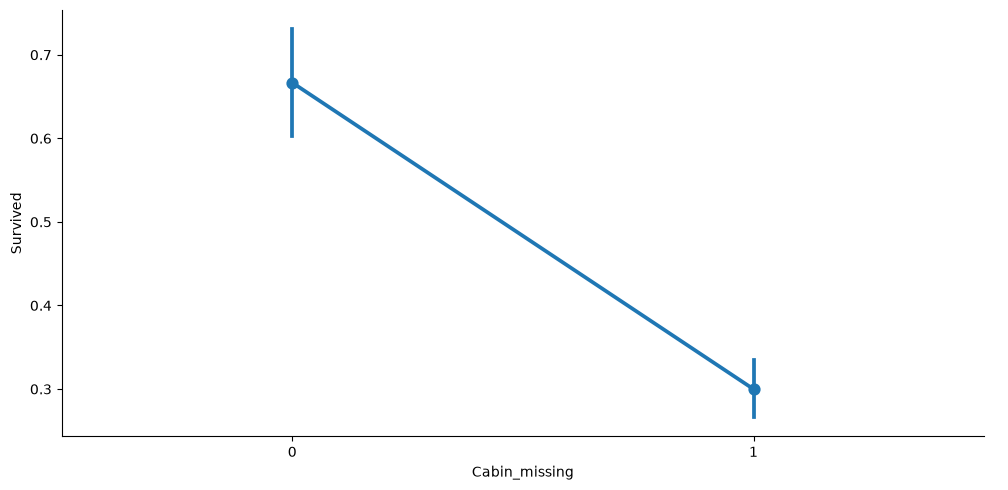

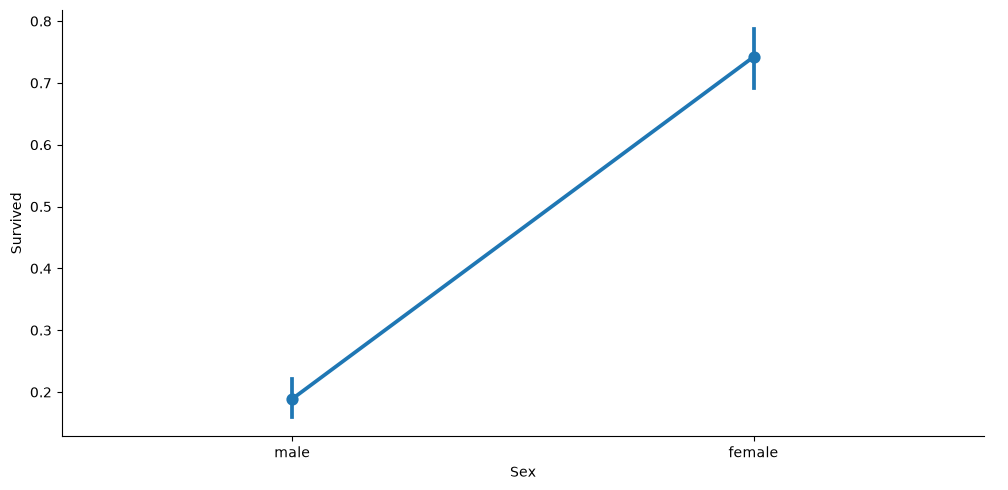

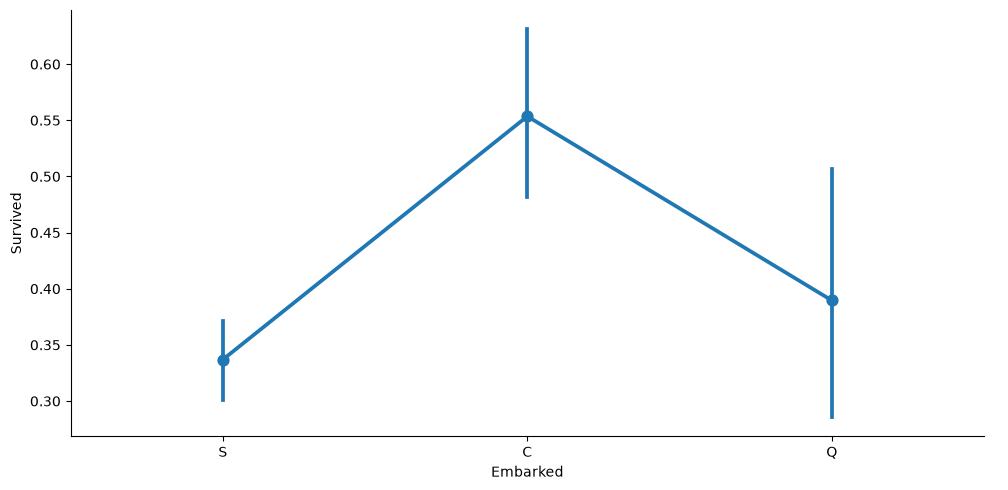

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

for i, col in enumerate(["Cabin_missing", "Sex", "Embarked"]):
    plt.figure(i)
    sns.catplot(x=col, y="Survived", data=df_train, kind="point", aspect=2)
    


Из первого графика можно увидеть информацию, которую мы уже получили, а именно, что люди у которых присутсвует запись о каюте выживают чаще.
Второй график показывает, что женщины выживали чаще мужчин.
Третий график показывает, что люди ступившие на борт из города "C" выживают чаще, а люди из города "S" наоборот. Это может быть связано с тем, что в одном городе зашло больше женщин или мужчин, а может быть с тем, что в каком-то городе цены на билет были ниже для 1го класса.

Для выявления этих "скрытых" признаков, воспользуемся сводной таблицей.

In [20]:
df_train.pivot_table("Survived", index="Sex", columns="Embarked", aggfunc="count")

Embarked,C,Q,S
Sex,,,
female,73,36,203
male,95,41,441


Из сводной таблицы видно, что в городе "S" на борт мужчин поднялось в 2 праза больше чем женщин. Это и объясняет низкую выживаемость у людей с этого города (что помог установить второй график).

Теперь проделаем эту же операцию, но с каютами.

In [21]:
df_train.pivot_table("Survived", index="Cabin_missing", columns="Embarked", aggfunc="count")

Embarked,C,Q,S
Cabin_missing,,,
0,69,4,129
1,99,73,515


Из полученных данных видно, что у людей из города "S" в 5 раз реже встречается упоминание номера каюты. Отсюда и заниженное значение у города "Q", люди из которого почти не получили номера каюты.
Из этих двух сводных таблиц мы сделали вывод, что признак Embarked всего лишь косвенно влияет на целевую метку, а значит от него можно избавиться.

Избавимся тауже от оставшегося признак "Ticket", который просто хранит в себе случайное значение.

In [28]:
df_train.drop(columns=["Embarked"], inplace=True)

In [24]:
df_train.drop(columns=["Ticket"], inplace=True)

In [25]:
df_train.head()

,Survived,Sex,Embarked,Cabin_missing
0,0,male,S,1
1,1,female,C,0
2,1,female,S,1
3,1,female,S,0
4,0,male,S,1


Так как моделям ML лучше всего работается с числовыми значениями, а не со словами, переведем признак Sex в бинарный вариант.

In [26]:
binary_gender = {"male": 0, "female": 1}
df_train["Sex"] = df_train["Sex"].map(binary_gender)

In [29]:
df_train.head()

,Survived,Sex,Cabin_missing
0,0,0,1
1,1,1,0
2,1,1,1
3,1,1,0
4,0,0,1


Проделаем все те же операции с трейновой выборкой.

In [30]:
df_test = pd.read_csv('DS/test.csv')
df_test.drop(cont_features, axis=1, inplace=True)

df_test["Cabin_missing"] = df_test["Cabin"].isnull().astype(int)
df_test.drop(columns=["Cabin"], inplace=True)

df_test.drop(columns=["Embarked"], inplace=True)
df_test.drop(columns=["Ticket"], inplace=True)

df_test["Sex"] = df_test["Sex"].map(binary_gender)

In [31]:
df_test.head()


,Sex,Cabin_missing
0,0,1
1,1,1
2,0,1
3,0,1
4,1,1
